# Bitcoin-Volatilität: Datenbasis und explorative Analyse

In diesem ersten Notebook-Teil bauen wir eine reproduzierbare Datenbasis für
die Prognose der zukünftigen realisierten Bitcoin-Volatilität auf. Wir laden
BTC-USD, Fear & Greed, VIX, DXY und Nasdaq, prüfen die Rohdaten, richten die
Zeitreihen ohne Look-ahead Leakage aus, definieren die Zielvariable und
untersuchen die wichtigsten Muster.

**Primäres Ziel:** zukünftige realisierte Volatilität über sieben Tage.

Wir reservieren die Daten ab 2025 als unberührten finalen Holdout. Am Ende
erzeugen wir eine kontrollierte Fold-Übersicht für den nächsten Notebook-Teil.
Die eigentlichen Modelle Naive, GARCH, XGBoost und Chronos-2 sind noch nicht
enthalten.

## Kurzfassung

Wir erstellen eine tägliche Modelling-Tabelle ab 2018 und verwenden nur
vollständig abgeschlossene Bitcoin-Tageskerzen im UTC-Kalender. Externe
Variablen verschieben wir konservativ um einen Tag, wenn der genaue
Veröffentlichungszeitpunkt nicht sicher ist.

EDA, Feature-Auswahl und Validierungsfolds verwenden ausschliesslich den
Entwicklungszeitraum bis Ende 2024. Trainingszeilen, deren siebentägiges
Zielfenster in eine Validation hineinreicht, werden später entfernt. Die
konkreten Daten- und Prüfergebnisse erscheinen direkt unter den ausgeführten
Zellen.

## 1. Setup

### Erklärung

Wir bündeln alle veränderbaren Parameter in einer Zelle. `DATA_END_DATE` ist
ein **exklusiver und fester UTC-Stichtag**: Der Datensatz endet somit am
18. Juli 2026, während der laufende UTC-Tag ausgeschlossen bleibt. Dadurch
erzeugen spätere Wiederholungen denselben historischen Ausschnitt.

Unser Prognosezeitpunkt liegt unmittelbar nach Abschluss der Bitcoin-UTC-
Tageskerze \(t\). Für spätere PyTorch-Modelle wählen wir auf Apple Silicon
automatisch `mps`, sofern es verfügbar ist. Die Datenaufbereitung läuft auf
der CPU.

In [1]:
from importlib.metadata import PackageNotFoundError, version
from pathlib import Path
import platform
import random

from IPython.display import Markdown, display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
import yfinance as yf

# Keep all configuration visible and reproducible
RANDOM_SEED = 42
START_DATE = "2018-02-01"
DATA_END_DATE = "2026-07-19"  # Exclusive UTC date; last included day is 2026-07-18
FORECAST_HORIZON = 7
FORECAST_TIMEZONE = "UTC"
HOLDOUT_START = pd.Timestamp("2025-01-01")
VALIDATION_YEARS = [2021, 2022, 2023, 2024]
EVALUATION_STEP_DAYS = 7

# Refuse a cutoff that could include a still-running UTC candle
data_end_timestamp = pd.Timestamp(DATA_END_DATE)
current_utc_day = pd.Timestamp.now(tz="UTC").normalize().tz_localize(None)
assert data_end_timestamp <= current_utc_day
last_included_date = data_end_timestamp - pd.Timedelta(days=1)

# Resolve paths whether Jupyter starts in the project root or notebooks folder
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
RAW_DATA_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)

# Make random operations reproducible
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# Use one consistent visual language throughout the notebook
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams.update(
    {
        "figure.figsize": (12, 5),
        "axes.titlesize": 14,
        "axes.labelsize": 11,
        "legend.frameon": False,
        "figure.dpi": 110,
    }
)
VIRIDIS = plt.colormaps["viridis"]
COLORS = {
    "btc": VIRIDIS(0.12),
    "volatility": VIRIDIS(0.38),
    "fear_greed": VIRIDIS(0.58),
    "vix": VIRIDIS(0.72),
    "dxy": VIRIDIS(0.84),
    "nasdaq": VIRIDIS(0.96),
}

# Detect MPS without moving pandas operations away from the CPU
try:
    import torch

    TORCH_VERSION = torch.__version__
    DEVICE = "mps" if torch.backends.mps.is_available() else "cpu"
except ImportError:
    torch = None
    TORCH_VERSION = "nicht installiert"
    DEVICE = "cpu"


def installed_version(package_name):
    '''Return a package version for the reproducibility table.'''
    try:
        return version(package_name)
    except PackageNotFoundError:
        return "nicht installiert"


# Show the environment instead of hiding setup assumptions
environment_table = pd.DataFrame(
    {
        "Komponente": [
            "Python",
            "Betriebssystem",
            "Prozessor",
            "PyTorch",
            "Gewähltes Gerät",
            "Forecast-Zeitzone",
            "Letzter Datentag",
            "Holdout ab",
            "pandas",
            "yfinance",
        ],
        "Wert": [
            platform.python_version(),
            platform.platform(),
            platform.machine(),
            TORCH_VERSION,
            DEVICE,
            FORECAST_TIMEZONE,
            last_included_date.date(),
            HOLDOUT_START.date(),
            installed_version("pandas"),
            installed_version("yfinance"),
        ],
    }
)
display(environment_table)

,Komponente,Wert
0,Python,3.11.13
1,Betriebssystem,macOS-26.5.2-arm64-arm-64bit
2,Prozessor,arm64
3,PyTorch,2.13.0
4,Gewähltes Gerät,mps
5,Forecast-Zeitzone,UTC
6,Letzter Datentag,2026-07-18
7,Holdout ab,2025-01-01
8,pandas,3.0.3
9,yfinance,1.5.1


### Interpretation

Wir verwenden einen festgelegten, vollständig abgeschlossenen Datenzeitraum.
MPS ist ausschliesslich für spätere PyTorch-Inferenz vorgesehen. pandas,
yfinance, GARCH und XGBoost bleiben auf der CPU. Die Tabelle dokumentiert
Stichtag, Holdout und tatsächlich verwendete Softwareumgebung.

## 2. Daten laden und prüfen

### Erklärung

Wir beziehen BTC-USD, VIX, DXY und Nasdaq über `yfinance`. Den Fear & Greed
Index laden wir über die öffentliche API von Alternative.me. Der Endzeitpunkt
von `yfinance.download()` ist exklusiv; `DATA_END_DATE = 2026-07-19` liefert
daher höchstens Daten bis zum abgeschlossenen UTC-Tag 18. Juli 2026.

Verwendete Yahoo-Symbole:

| Inhalt | Symbol |
|---|---|
| Bitcoin in USD | `BTC-USD` |
| VIX | `^VIX` |
| US-Dollar-Index | `DX-Y.NYB` |
| Nasdaq Composite | `^IXIC` |

Wir speichern die Rohdaten lokal. Ein Cache wird nur wiederverwendet, wenn er
nach Ende des letzten eingeschlossenen UTC-Tages erstellt wurde und sämtliche
Qualitätsregeln erfüllt. Andernfalls laden wir ihn neu.

In [2]:
YAHOO_SERIES = {
    "btc": {"ticker": "BTC-USD", "columns": ["Open", "High", "Low", "Close", "Volume"]},
    "vix": {"ticker": "^VIX", "columns": ["Close"]},
    "dxy": {"ticker": "DX-Y.NYB", "columns": ["Close"]},
    "nasdaq": {"ticker": "^IXIC", "columns": ["Close"]},
}


def validate_source_frame(frame, series_name):
    '''Validate chronology, completeness and stable domain rules.'''
    # Check the common daily-series contract first
    assert not frame.empty, f"{series_name}: keine Daten"
    assert frame.index.is_monotonic_increasing, f"{series_name}: Datum nicht sortiert"
    assert frame.index.is_unique, f"{series_name}: doppelte Datumswerte"
    assert frame.index.min() >= pd.Timestamp(START_DATE), f"{series_name}: Datum vor Start"
    assert frame.index.max() < data_end_timestamp, f"{series_name}: unvollständiger Endtag"
    assert frame.notna().all().all(), f"{series_name}: fehlende Rohwerte"
    assert np.isfinite(frame.select_dtypes("number")).all().all(), f"{series_name}: nicht endliche Werte"

    if series_name == "btc":
        # Bitcoin must contain every UTC calendar day in the selected period
        expected_days = pd.date_range(frame.index.min(), frame.index.max(), freq="D")
        assert frame.index.equals(expected_days), "btc: fehlende oder zusätzliche Kalendertage"

        # Enforce basic OHLCV market-data identities
        price_columns = ["btc_open", "btc_high", "btc_low", "btc_close"]
        assert (frame[price_columns] > 0).all().all(), "btc: nicht positive Preise"
        assert (frame["btc_volume"] >= 0).all(), "btc: negatives Volumen"
        assert (
            frame["btc_high"] >= frame[["btc_open", "btc_close", "btc_low"]].max(axis=1)
        ).all(), "btc: High liegt unter Open, Close oder Low"
        assert (
            frame["btc_low"] <= frame[["btc_open", "btc_close", "btc_high"]].min(axis=1)
        ).all(), "btc: Low liegt über Open, Close oder High"

    if series_name == "fear_greed":
        assert frame["fear_greed"].between(0, 100).all(), "fear_greed: Wert ausserhalb 0-100"

    if series_name in {"vix", "dxy", "nasdaq"}:
        assert (frame.iloc[:, 0] > 0).all(), f"{series_name}: nicht positive Indexwerte"


def cache_is_usable(cache_path, frame, series_name):
    '''Return whether a cached extract is complete and valid.'''
    # A cache written before the exclusive cutoff may contain a running candle
    cache_written_utc = pd.Timestamp(cache_path.stat().st_mtime, unit="s", tz="UTC")
    cutoff_utc = pd.Timestamp(DATA_END_DATE, tz="UTC")
    if cache_written_utc < cutoff_utc:
        return False

    try:
        validate_source_frame(frame, series_name)
    except AssertionError:
        return False
    return True


def load_yahoo_series(series_name, ticker, columns):
    '''Load one Yahoo series from a validated cache or download it.'''
    # Include the date range in the cache name to keep extracts traceable
    safe_ticker = ticker.replace("^", "").replace("=", "_").replace(".", "_")
    cache_path = RAW_DATA_DIR / f"{series_name}_{safe_ticker}_{START_DATE}_{DATA_END_DATE}.csv"

    if cache_path.exists():
        # Reuse only a cache created after the final included candle closed
        cached = pd.read_csv(cache_path, parse_dates=["date"]).set_index("date")
        if cache_is_usable(cache_path, cached, series_name):
            return cached
        print(f"{series_name}: veralteter oder ungültiger Cache wird neu geladen.")

    # Download one ticker at a time to avoid unnecessary MultiIndex handling
    downloaded = yf.download(
        ticker,
        start=START_DATE,
        end=DATA_END_DATE,
        interval="1d",
        auto_adjust=False,
        repair=False,
        progress=False,
        threads=False,
        timeout=30,
        multi_level_index=False,
    )
    if downloaded.empty:
        raise RuntimeError(f"Keine Yahoo-Daten für {ticker} erhalten.")

    # Interpret every daily index as a UTC calendar date
    downloaded.index = (
        pd.to_datetime(downloaded.index, utc=True).tz_convert(None).normalize()
    )
    downloaded.index.name = "date"
    frame = downloaded.loc[:, columns].copy()
    frame.columns = [f"{series_name}_{column.lower().replace(' ', '_')}" for column in columns]

    # Validate before replacing a stale cache
    validate_source_frame(frame, series_name)
    frame.reset_index().to_csv(cache_path, index=False)
    return frame


def load_fear_greed():
    '''Load the complete Fear & Greed history from cache or the public API.'''
    cache_path = RAW_DATA_DIR / f"fear_greed_{START_DATE}_{DATA_END_DATE}.csv"

    if cache_path.exists():
        cached = pd.read_csv(cache_path, parse_dates=["date"]).set_index("date")
        if cache_is_usable(cache_path, cached, "fear_greed"):
            return cached
        print("fear_greed: veralteter oder ungültiger Cache wird neu geladen.")

    # Request the full daily history in JSON format
    response = requests.get(
        "https://api.alternative.me/fng/",
        params={"limit": 0, "format": "json"},
        headers={"User-Agent": "CSP1 educational time-series project"},
        timeout=30,
    )
    response.raise_for_status()
    payload = response.json()
    assert "data" in payload and payload["data"], "Fear & Greed API ohne Daten"

    # Convert Unix timestamps explicitly from UTC into daily dates
    frame = pd.DataFrame(payload["data"])
    frame["date"] = (
        pd.to_datetime(frame["timestamp"].astype("int64"), unit="s", utc=True)
        .dt.tz_convert(None)
        .dt.normalize()
    )
    frame["fear_greed"] = pd.to_numeric(frame["value"], errors="coerce")
    frame = frame.set_index("date")[["fear_greed"]].sort_index()
    frame = frame.loc[(frame.index >= START_DATE) & (frame.index < DATA_END_DATE)]

    # Validate before replacing a stale cache
    validate_source_frame(frame, "fear_greed")
    frame.reset_index().to_csv(cache_path, index=False)
    return frame

In [3]:
# Download or reuse all requested market series
loaded_series = {
    name: load_yahoo_series(name, settings["ticker"], settings["columns"])
    for name, settings in YAHOO_SERIES.items()
}
loaded_series["fear_greed"] = load_fear_greed()

# Use explicit names for the following analysis steps
btc = loaded_series["btc"]
vix = loaded_series["vix"]
dxy = loaded_series["dxy"]
nasdaq = loaded_series["nasdaq"]
fear_greed = loaded_series["fear_greed"]

# Re-run every source contract visibly before the analysis
source_rows = []
for source_name, frame in loaded_series.items():
    validate_source_frame(frame, source_name)
    source_rows.append(
        {
            "Quelle": source_name,
            "Erster Tag": frame.index.min().date(),
            "Letzter Tag": frame.index.max().date(),
            "Zeilen": len(frame),
            "Doppelte Tage": int(frame.index.duplicated().sum()),
            "Fehlende Werte": int(frame.isna().sum().sum()),
            "Status": "bestanden",
        }
    )

source_summary = pd.DataFrame(source_rows)
display(source_summary)

# Show the latest Bitcoin rows so completed-candle checks remain inspectable
display(btc.tail(3).round(2))

,Quelle,Erster Tag,Letzter Tag,Zeilen,Doppelte Tage,Fehlende Werte,Status
0,btc,2018-02-01,2026-07-18,3090,0,0,bestanden
1,vix,2018-02-01,2026-07-17,2126,0,0,bestanden
2,dxy,2018-02-01,2026-07-17,2127,0,0,bestanden
3,nasdaq,2018-02-01,2026-07-17,2125,0,0,bestanden
4,fear_greed,2018-02-01,2026-07-18,3086,0,0,bestanden


,btc_open,btc_high,btc_low,btc_close,btc_volume
date,,,,,
2026-07-16,64713.30,64931.86,63701.80,63789.28,27232426674
2026-07-17,63789.91,64332.02,62489.45,63899.46,27280236800
2026-07-18,63899.18,64816.50,63845.02,64796.60,14162542470


In [4]:
# Build the interpretation from observed and validated data
btc_days = len(btc)
calendar_days = (btc.index.max() - btc.index.min()).days + 1
coverage_ratio = btc_days / calendar_days
btc_days_display = f"{btc_days:,}".replace(",", "'")

display(
    Markdown(
        f'''
### Interpretation

Alle fünf Rohdatenquellen bestehen die Prüfungen auf Chronologie, eindeutige
Tage, fehlende und nicht endliche Werte sowie ihre jeweiligen Wertebereiche.
Für Bitcoin gelten zusätzlich die OHLCV-Regeln. Wir verfügen über
**{btc_days_display} vollständig abgeschlossene Bitcoin-Tagesbeobachtungen**
vom **{btc.index.min().date()}** bis **{btc.index.max().date()}** bei einer
Kalenderabdeckung von {coverage_ratio:.1%}.
'''
    )
)


### Interpretation

Alle fünf Rohdatenquellen bestehen die Prüfungen auf Chronologie, eindeutige
Tage, fehlende und nicht endliche Werte sowie ihre jeweiligen Wertebereiche.
Für Bitcoin gelten zusätzlich die OHLCV-Regeln. Wir verfügen über
**3'090 vollständig abgeschlossene Bitcoin-Tagesbeobachtungen**
vom **2018-02-01** bis **2026-07-18** bei einer
Kalenderabdeckung von 100.0%.


## 3. Daten zeitlich ausrichten

### Erklärung

Unser Prognoseursprung \(t\) liegt unmittelbar nach Abschluss der
Bitcoin-Tageskerze im UTC-Kalender. Bitcoin wird täglich gehandelt, die
traditionellen Märkte dagegen nur an Handelstagen. Wir verwenden deshalb den
Bitcoin-Kalender als Grundgerüst und tragen traditionelle Marktwerte höchstens
vier Kalendertage vorwärts.

Anschliessend verschieben wir **alle externen Variablen um einen Tag**. Damit
verwenden wir am Prognoseursprung nur Werte, die unabhängig vom exakten
Publikationszeitpunkt sicher verfügbar waren:

$$
x^{\mathrm{verwendet}}_t = x^{\mathrm{beobachtet}}_{t-1}
$$

Die Namen `fear_greed_lag_1` und ähnliche spätere Lags bezeichnen eine
zusätzliche Verzögerung relativ zu diesem bereits konservativ verfügbaren Wert.

In [5]:
# Join every source to the daily Bitcoin calendar
aligned = btc.join([fear_greed, vix, dxy, nasdaq], how="left")
external_columns = ["fear_greed", "vix_close", "dxy_close", "nasdaq_close"]

# Record missingness before calendar alignment
missing_before = aligned[external_columns].isna().sum()

# Fill only short calendar gaps caused by weekends and common holidays
aligned["fear_greed"] = aligned["fear_greed"].ffill(limit=2)
aligned[["vix_close", "dxy_close", "nasdaq_close"]] = aligned[
    ["vix_close", "dxy_close", "nasdaq_close"]
].ffill(limit=4)

# Shift external information by one day to enforce conservative availability
aligned[external_columns] = aligned[external_columns].shift(1)

# Keep remaining long gaps visible for later fold-specific preprocessing
missing_after = aligned[external_columns].isna().sum()
missing_table = pd.DataFrame(
    {
        "Vor Ausrichtung": missing_before,
        "Nach Füllen und Shift": missing_after,
        "Veränderung": missing_after - missing_before,
    }
)
display(missing_table)
display(aligned.head(5).round(2))

,Vor Ausrichtung,Nach Füllen und Shift,Veränderung
fear_greed,4,2,-2
vix_close,964,1,-963
dxy_close,963,1,-962
nasdaq_close,965,1,-964


,btc_open,btc_high,btc_low,btc_close,btc_volume,fear_greed,vix_close,dxy_close,nasdaq_close
date,,,,,,,,,
2018-02-01,10237.30,10288.80,8812.28,9170.54,9959400448,NaN,NaN,NaN,NaN
2018-02-02,9142.28,9142.28,7796.49,8830.75,12726899712,30.0,13.47,88.67,7385.86
2018-02-03,8852.12,9430.75,8251.63,9174.91,7263790080,15.0,17.31,89.20,7240.95
2018-02-04,9175.70,9334.87,8031.22,8277.01,7073549824,40.0,17.31,89.20,7240.95
2018-02-05,8270.54,8364.84,6756.68,6955.27,9285289984,24.0,17.31,89.20,7240.95


In [6]:
# Explain whether any long gaps remain after conservative alignment
remaining_missing = int(missing_after.sum())
affected_rows = int(aligned[external_columns].isna().any(axis=1).sum())

display(
    Markdown(
        f'''
### Interpretation

Nach der Ausrichtung verbleiben **{remaining_missing} fehlende externe
Einzelwerte** in **{affected_rows} Zeilen**. Dazu gehören mindestens die ersten
Beobachtungen, weil durch den Sicherheits-Shift noch kein Vortageswert
existiert. Wir löschen diese Zeilen erst nach dem Feature Engineering. Dadurch
bleibt jeder Datenverlust transparent und wir vermeiden eine globale
Interpolation über längere Lücken.
'''
    )
)


### Interpretation

Nach der Ausrichtung verbleiben **5 fehlende externe
Einzelwerte** in **2 Zeilen**. Dazu gehören mindestens die ersten
Beobachtungen, weil durch den Sicherheits-Shift noch kein Vortageswert
existiert. Wir löschen diese Zeilen erst nach dem Feature Engineering. Dadurch
bleibt jeder Datenverlust transparent und wir vermeiden eine globale
Interpolation über längere Lücken.


## 4. Zielvariable konstruieren

### Erklärung

Wir berechnen zuerst den logarithmischen Tagesreturn aus dem Bitcoin-Schlusskurs
\(P_t\):

$$
r_t = \log\left(\frac{P_t}{P_{t-1}}\right)
$$

Die primäre Zielvariable ist die **zukünftige realisierte Volatilität über
sieben Tage**. Für einen Prognosezeitpunkt \(t\) verwenden wir ausschliesslich
die zukünftigen Returns \(t+1,\ldots,t+7\):

$$
\mathrm{RV}_{t,7} =
\sqrt{\sum_{i=1}^{7} r_{t+i}^{2}}
$$

Zum Vergleich berechnen wir auch die historische, rückwärts blickende
7-Tage-Volatilität. Sie ist am Tag \(t\) bekannt und darf später als Feature
oder naive Persistenzprognose verwendet werden.

In [7]:
# Calculate daily log returns from unadjusted Bitcoin close prices
aligned["btc_log_return"] = np.log(aligned["btc_close"] / aligned["btc_close"].shift(1))
aligned["btc_squared_return"] = aligned["btc_log_return"].pow(2)

# Create backward-looking realized volatility available at forecast time
aligned["rv_7"] = np.sqrt(
    aligned["btc_squared_return"].rolling(7, min_periods=7).sum()
)

# Reverse the shifted series so rolling sums look forward in original time
future_squared_returns = aligned["btc_squared_return"].shift(-1)
aligned["target_rv_7"] = np.sqrt(
    future_squared_returns.iloc[::-1]
    .rolling(FORECAST_HORIZON, min_periods=FORECAST_HORIZON)
    .sum()
    .iloc[::-1]
)

# Keep the one-day target as a transparent secondary outcome
aligned["target_rv_1"] = np.sqrt(aligned["btc_squared_return"].shift(-1))

# Annualize only for reader-friendly plots, not for the model comparison
aligned["rv_7_annualized"] = aligned["rv_7"] * np.sqrt(365 / 7)
aligned["target_rv_7_annualized"] = aligned["target_rv_7"] * np.sqrt(365 / 7)

# Show observations with fully known historical and future windows
target_preview = aligned[
    ["btc_close", "btc_log_return", "rv_7", "target_rv_1", "target_rv_7"]
].dropna().tail(5)
display(target_preview.round(4))

,btc_close,btc_log_return,rv_7,target_rv_1,target_rv_7
date,,,,,
2026-07-07,63297.3945,-0.0110,0.0422,0.0166,0.0561
2026-07-08,62257.5742,-0.0166,0.0382,0.0149,0.0537
2026-07-09,63193.1484,0.0149,0.0329,0.0147,0.0536
2026-07-10,64127.1406,0.0147,0.0318,0.0051,0.0515
2026-07-11,63802.0273,-0.0051,0.0310,0.0007,0.0532


In [8]:
# Recalculate every future target with an independent explicit loop
direct_targets = []
for position in range(len(aligned)):
    future_returns = aligned["btc_log_return"].iloc[
        position + 1 : position + 1 + FORECAST_HORIZON
    ]
    if len(future_returns) == FORECAST_HORIZON and future_returns.notna().all():
        direct_targets.append(np.sqrt(np.square(future_returns).sum()))
    else:
        direct_targets.append(np.nan)

direct_target_series = pd.Series(direct_targets, index=aligned.index)
comparison_mask = aligned["target_rv_7"].notna() & direct_target_series.notna()
target_differences = (
    aligned.loc[comparison_mask, "target_rv_7"]
    - direct_target_series.loc[comparison_mask]
).abs()

# Fail immediately if any target is shifted to the wrong date
max_target_difference = target_differences.max()
assert max_target_difference < 1e-12, "Die Zielvariable ist zeitlich falsch ausgerichtet."

target_check = pd.DataFrame(
    {
        "Prüfung": [
            "Verglichene Zielwerte",
            "Maximale absolute Differenz",
            "Erster gültiger Prognosetag",
            "Letzter gültiger Prognosetag",
        ],
        "Wert": [
            int(comparison_mask.sum()),
            max_target_difference,
            aligned.loc[comparison_mask].index.min().date(),
            aligned.loc[comparison_mask].index.max().date(),
        ],
    }
)
display(target_check)

,Prüfung,Wert
0,Verglichene Zielwerte,3083
1,Maximale absolute Differenz,0.0
2,Erster gültiger Prognosetag,2018-02-01
3,Letzter gültiger Prognosetag,2026-07-11


In [9]:
# Summarize only targets that end before the untouched holdout
development_target_mask = (
    aligned.index + pd.Timedelta(days=FORECAST_HORIZON) < HOLDOUT_START
)
development_targets = aligned.loc[development_target_mask, "target_rv_7"].dropna()
target_stats = development_targets.describe()
target_count_display = f"{int(comparison_mask.sum()):,}".replace(",", "'")

display(
    Markdown(
        f'''
### Interpretation

Die unabhängige Kontrollrechnung stimmt für **{target_count_display}**
Zielwerte mit der vektorisierten Berechnung überein; die maximale Differenz
beträgt **{max_target_difference:.2e}**. Im Entwicklungszeitraum beträgt die
mediane nicht annualisierte 7-Tage-Volatilität **{target_stats['50%']:.3f}**,
das 90%-Quantil **{development_targets.quantile(0.90):.3f}**. Die letzten
sieben Zeilen des Gesamtdatensatzes besitzen definitionsgemäss noch kein
vollständiges zukünftiges Zielfenster.
'''
    )
)


### Interpretation

Die unabhängige Kontrollrechnung stimmt für **3'083**
Zielwerte mit der vektorisierten Berechnung überein; die maximale Differenz
beträgt **3.54e-15**. Im Entwicklungszeitraum beträgt die
mediane nicht annualisierte 7-Tage-Volatilität **0.071**,
das 90%-Quantil **0.135**. Die letzten
sieben Zeilen des Gesamtdatensatzes besitzen definitionsgemäss noch kein
vollständiges zukünftiges Zielfenster.


## 5. Features erzeugen

### Erklärung

Wir verwenden nur rückwärts blickende Merkmale. Dazu gehören Returns,
Handelsspanne, Volumen, rollierende historische Volatilität und verzögerte
Werte. Für VIX, DXY und Nasdaq berechnen wir Veränderungen auf den bereits um
einen Tag verschobenen Reihen.

Fear & Greed und das VIX-Niveau bleiben als interpretierbare Zustandsmerkmale
enthalten. Die stark trendenden absoluten DXY- und Nasdaq-Niveaus schliessen
wir aus dem Haupt-Feature-Set aus; ihre Returns und 7-/14-Tage-Veränderungen
bleiben enthalten. Eine spätere Skalierung oder Imputation muss innerhalb des
jeweiligen Trainingsfolds gelernt werden.

In [10]:
modeling_data = aligned.copy()

# Add simple Bitcoin features available at the end of each day
modeling_data["btc_abs_return"] = modeling_data["btc_log_return"].abs()
modeling_data["btc_high_low_range"] = (
    modeling_data["btc_high"] - modeling_data["btc_low"]
) / modeling_data["btc_close"]
modeling_data["btc_volume_log"] = np.log1p(modeling_data["btc_volume"])

# Add backward-looking volatility windows
for window in [14, 30]:
    modeling_data[f"rv_{window}"] = np.sqrt(
        modeling_data["btc_squared_return"].rolling(window, min_periods=window).sum()
    )

# Add explicit return and volatility lags
for lag in [1, 2, 3, 7, 14]:
    modeling_data[f"btc_log_return_lag_{lag}"] = modeling_data["btc_log_return"].shift(lag)
    modeling_data[f"rv_7_lag_{lag}"] = modeling_data["rv_7"].shift(lag)

# Calculate changes from already delayed external market levels
for column in ["vix_close", "dxy_close", "nasdaq_close"]:
    base_name = column.replace("_close", "")
    modeling_data[f"{base_name}_return_1d"] = modeling_data[column].pct_change(fill_method=None)
    modeling_data[f"{base_name}_change_7d"] = modeling_data[column].pct_change(
        periods=7, fill_method=None
    )
    modeling_data[f"{base_name}_change_14d"] = modeling_data[column].pct_change(
        periods=14, fill_method=None
    )

# Add sentiment lags and absolute changes
modeling_data["fear_greed_lag_1"] = modeling_data["fear_greed"].shift(1)
modeling_data["fear_greed_change_7d"] = modeling_data["fear_greed"].diff(7)
modeling_data["fear_greed_change_14d"] = modeling_data["fear_greed"].diff(14)

# Keep raw trending DXY and Nasdaq levels out of the main feature set
feature_columns = [
    "btc_log_return",
    "btc_abs_return",
    "btc_squared_return",
    "btc_high_low_range",
    "btc_volume_log",
    "rv_7",
    "rv_14",
    "rv_30",
    *[f"btc_log_return_lag_{lag}" for lag in [1, 2, 3, 7, 14]],
    *[f"rv_7_lag_{lag}" for lag in [1, 2, 3, 7, 14]],
    "fear_greed",
    "fear_greed_lag_1",
    "fear_greed_change_7d",
    "fear_greed_change_14d",
    "vix_close",
    "vix_return_1d",
    "vix_change_7d",
    "vix_change_14d",
    "dxy_return_1d",
    "dxy_change_7d",
    "dxy_change_14d",
    "nasdaq_return_1d",
    "nasdaq_change_7d",
    "nasdaq_change_14d",
]
target_columns = ["target_rv_1", "target_rv_7"]

# Remove only rows that cannot support the complete current feature set
modeling_table = modeling_data[feature_columns + target_columns].dropna().copy()
modeling_table["target_end"] = (
    modeling_table.index + pd.Timedelta(days=FORECAST_HORIZON)
)

# Purge development labels that reach the untouched holdout
development_table = modeling_table[
    modeling_table["target_end"] < HOLDOUT_START
].copy()
holdout_table = modeling_table[
    modeling_table.index >= HOLDOUT_START
].copy()
holdout_boundary_rows = modeling_table[
    (modeling_table.index < HOLDOUT_START)
    & (modeling_table["target_end"] >= HOLDOUT_START)
].copy()

# Save a reproducible handoff for the later modeling notebook
processed_path = PROCESSED_DATA_DIR / "bitcoin_volatility_modeling_table.csv"
modeling_table.to_csv(processed_path, index_label="date")

feature_summary = pd.DataFrame(
    {
        "Kennzahl": [
            "Gesamte Beobachtungen",
            "Entwicklungsbeobachtungen",
            "Am Holdout-Rand gepurgte Beobachtungen",
            "Reservierte Holdout-Beobachtungen",
            "Features",
            "Erster Prognosetag",
            "Letzter Prognosetag",
            "Fehlende Werte",
        ],
        "Wert": [
            len(modeling_table),
            len(development_table),
            len(holdout_boundary_rows),
            len(holdout_table),
            len(feature_columns),
            modeling_table.index.min().date(),
            modeling_table.index.max().date(),
            int(modeling_table.isna().sum().sum()),
        ],
    }
)
display(feature_summary)

# Round only numeric columns so datetime metadata remains unchanged
development_preview = development_table.head(3).copy()
numeric_preview_columns = development_preview.select_dtypes("number").columns
development_preview[numeric_preview_columns] = development_preview[
    numeric_preview_columns
].round(4)
display(development_preview)

,Kennzahl,Wert
0,Gesamte Beobachtungen,3049
1,Entwicklungsbeobachtungen,2485
2,Am Holdout-Rand gepurgte Beobachtungen,7
3,Reservierte Holdout-Beobachtungen,557
4,Features,32
5,Erster Prognosetag,2018-03-03
6,Letzter Prognosetag,2026-07-11
7,Fehlende Werte,0


,btc_log_return,btc_abs_return,btc_squared_return,btc_high_low_range,btc_volume_log,rv_7,rv_14,rv_30,btc_log_return_lag_1,btc_log_return_lag_2,...,vix_change_14d,dxy_return_1d,dxy_change_7d,dxy_change_14d,nasdaq_return_1d,nasdaq_change_7d,nasdaq_change_14d,target_rv_1,target_rv_7,target_end
date,,,,,,,,,,,,,,,,,,,,,
2018-03-03,0.0357,0.0357,0.0013,0.0458,22.6240,0.1067,0.1729,0.3613,0.0123,0.0518,...,0.0067,-0.0042,0.0007,0.0094,0.0108,-0.0108,0.0025,0.0020,0.1321,2018-03-10
2018-03-04,0.0020,0.0020,0.0000,0.0327,22.5290,0.1056,0.1650,0.3594,0.0357,0.0123,...,0.0067,0.0000,0.0007,0.0094,0.0000,-0.0108,0.0025,0.0053,0.1530,2018-03-11
2018-03-05,0.0053,0.0053,0.0000,0.0225,22.5902,0.0792,0.1531,0.3574,0.0020,0.0357,...,0.0067,0.0000,0.0007,0.0094,0.0000,-0.0108,0.0025,0.0710,0.1580,2018-03-12


In [11]:
# Validate the final table and the development-holdout boundary
expected_last_target_date = aligned.index[-(FORECAST_HORIZON + 1)]
actual_last_target_date = modeling_table.index.max()
assert actual_last_target_date <= expected_last_target_date
assert modeling_table.index.is_unique
assert modeling_table.index.is_monotonic_increasing
assert modeling_table.drop(columns=["target_end"]).notna().all().all()
assert np.isfinite(
    modeling_table.drop(columns=["target_end"]).select_dtypes("number")
).all().all()
assert (development_table["target_end"] < HOLDOUT_START).all()
assert (holdout_boundary_rows["target_end"] >= HOLDOUT_START).all()
assert (holdout_table.index >= HOLDOUT_START).all()

modeling_rows_display = f"{len(modeling_table):,}".replace(",", "'")
development_rows_display = f"{len(development_table):,}".replace(",", "'")

display(
    Markdown(
        f'''
### Interpretation

Die Modelling-Tabelle enthält **{modeling_rows_display} Beobachtungen** und
**{len(feature_columns)} Features** ohne fehlende oder unendliche Werte.
Davon stehen **{development_rows_display} Zeilen** für EDA und
Modellentwicklung zur Verfügung. Alle Entwicklungslabels enden vor dem
Holdout ab **{HOLDOUT_START.date()}**. Die
**{len(holdout_boundary_rows)} überlappenden Randzeilen** sind explizit
gepurgt. Die Holdout-Zielwerte werden in diesem Notebook weder analysiert noch
zur Feature-Auswahl verwendet.
'''
    )
)


### Interpretation

Die Modelling-Tabelle enthält **3'049 Beobachtungen** und
**32 Features** ohne fehlende oder unendliche Werte.
Davon stehen **2'485 Zeilen** für EDA und
Modellentwicklung zur Verfügung. Alle Entwicklungslabels enden vor dem
Holdout ab **2025-01-01**. Die
**7 überlappenden Randzeilen** sind explizit
gepurgt. Die Holdout-Zielwerte werden in diesem Notebook weder analysiert noch
zur Feature-Auswahl verwendet.


## 6. Explorative Datenanalyse

Alle EDA-Berechnungen verwenden ausschliesslich den Entwicklungszeitraum vor
dem finalen Holdout.

### 6.1 Bitcoin-Preis, Returns und Volatilität

#### Erklärung

Wir prüfen, ob die typischen Merkmale einer Finanzzeitreihe sichtbar sind:
ein nichtstationärer Preis, stark schwankende Returns und zeitlich gehäufte
Volatilitätsphasen. Für die Modellierung interessiert uns besonders, ob grosse
absolute Returns aufeinander folgen.

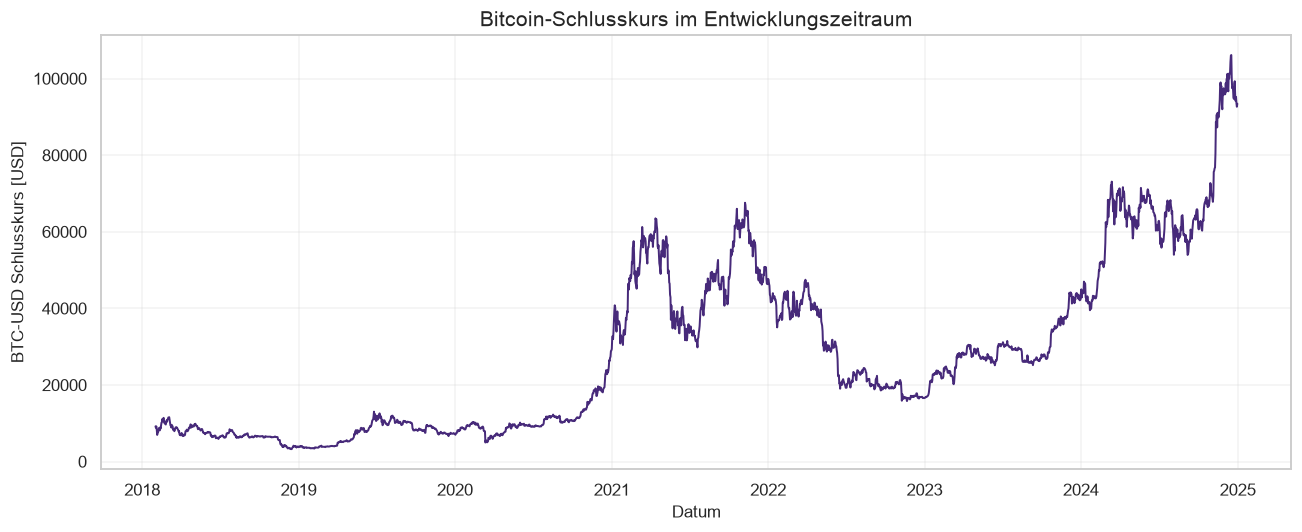

In [12]:
# Restrict all exploratory plots to the development period
eda_aligned = aligned.loc[aligned.index < HOLDOUT_START].copy()

# Plot the price separately because its scale differs from returns
fig, ax = plt.subplots()
ax.plot(eda_aligned.index, eda_aligned["btc_close"], color=COLORS["btc"], linewidth=1.3)
ax.set_title("Bitcoin-Schlusskurs im Entwicklungszeitraum")
ax.set_xlabel("Datum")
ax.set_ylabel("BTC-USD Schlusskurs [USD]")
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

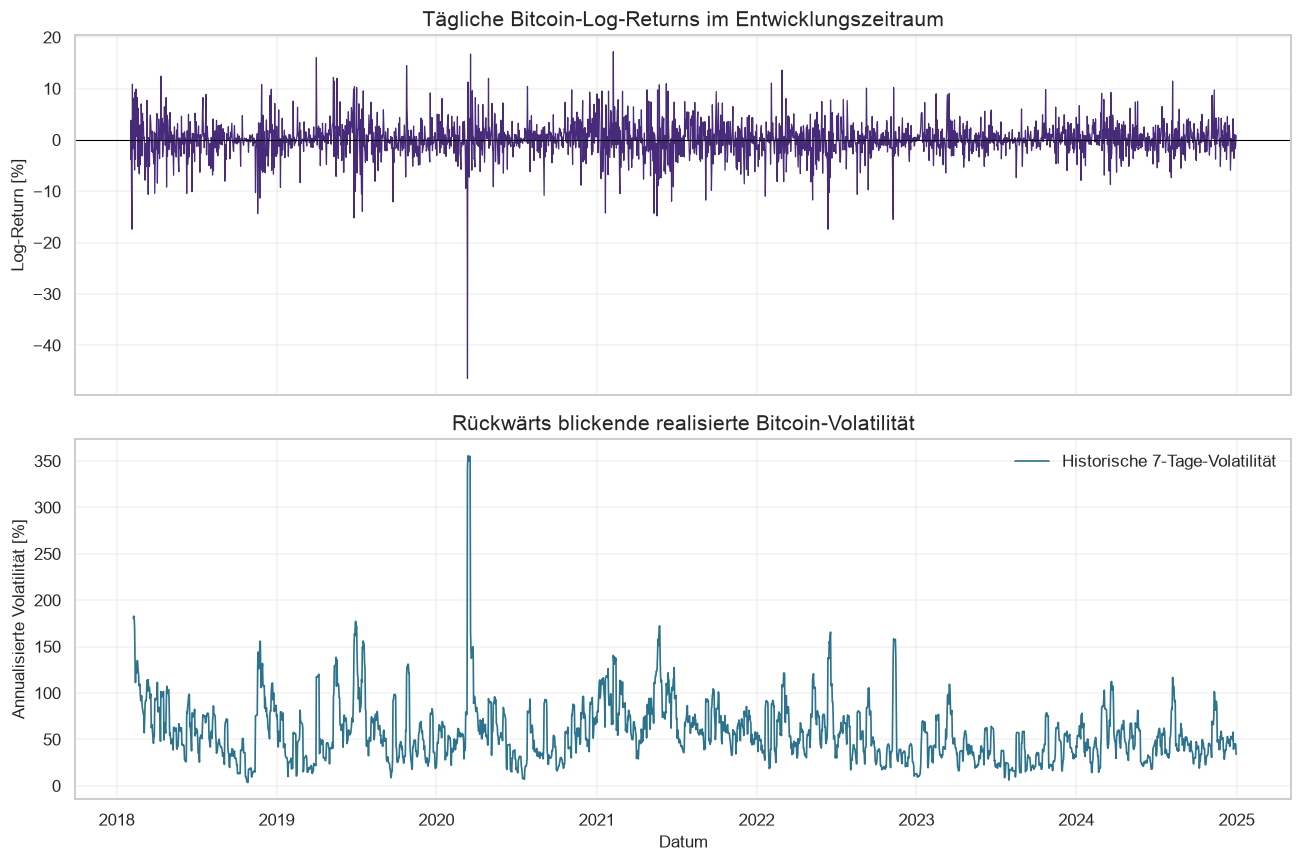

In [13]:
# Compare daily returns with backward-looking annualized volatility
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes[0].plot(
    eda_aligned.index,
    eda_aligned["btc_log_return"] * 100,
    color=COLORS["btc"],
    linewidth=0.8,
)
axes[0].axhline(0, color="black", linewidth=0.7)
axes[0].set_title("Tägliche Bitcoin-Log-Returns im Entwicklungszeitraum")
axes[0].set_ylabel("Log-Return [%]")
axes[0].grid(alpha=0.25)

axes[1].plot(
    eda_aligned.index,
    eda_aligned["rv_7_annualized"] * 100,
    color=COLORS["volatility"],
    linewidth=1.1,
    label="Historische 7-Tage-Volatilität",
)
axes[1].set_title("Rückwärts blickende realisierte Bitcoin-Volatilität")
axes[1].set_xlabel("Datum")
axes[1].set_ylabel("Annualisierte Volatilität [%]")
axes[1].legend()
axes[1].grid(alpha=0.25)

fig.tight_layout()
plt.show()

In [14]:
# Quantify volatility clustering only in the development period
abs_return_autocorrelation = development_table["btc_abs_return"].autocorr(lag=1)
peak_volatility_date = eda_aligned["rv_7_annualized"].idxmax()
peak_volatility = eda_aligned.loc[peak_volatility_date, "rv_7_annualized"] * 100

display(
    Markdown(
        f'''
#### Interpretation

Im Entwicklungszeitraum erkennen wir deutlich wechselnde Volatilitätsregime.
Die höchste rückwärts blickende annualisierte 7-Tage-Volatilität liegt am
**{peak_volatility_date.date()}** bei **{peak_volatility:.1f}%**. Die
Lag-1-Autokorrelation der absoluten Returns beträgt
**{abs_return_autocorrelation:.2f}**. Ein positiver Wert unterstützt die
Annahme von Volatilitätsclustering und damit den späteren Vergleich mit GARCH.
'''
    )
)


#### Interpretation

Im Entwicklungszeitraum erkennen wir deutlich wechselnde Volatilitätsregime.
Die höchste rückwärts blickende annualisierte 7-Tage-Volatilität liegt am
**2020-03-14** bei **355.7%**. Die
Lag-1-Autokorrelation der absoluten Returns beträgt
**0.14**. Ein positiver Wert unterstützt die
Annahme von Volatilitätsclustering und damit den späteren Vergleich mit GARCH.


### 6.2 Verteilung der Zielvariable

#### Erklärung

Wir betrachten die Verteilung von \(\mathrm{RV}_{t,7}\), weil starke
Rechtsschiefe und Ausreisser die Modellwahl und den Unterschied zwischen MAE
und RMSE beeinflussen. RMSE gewichtet grosse Fehler stärker als MAE.

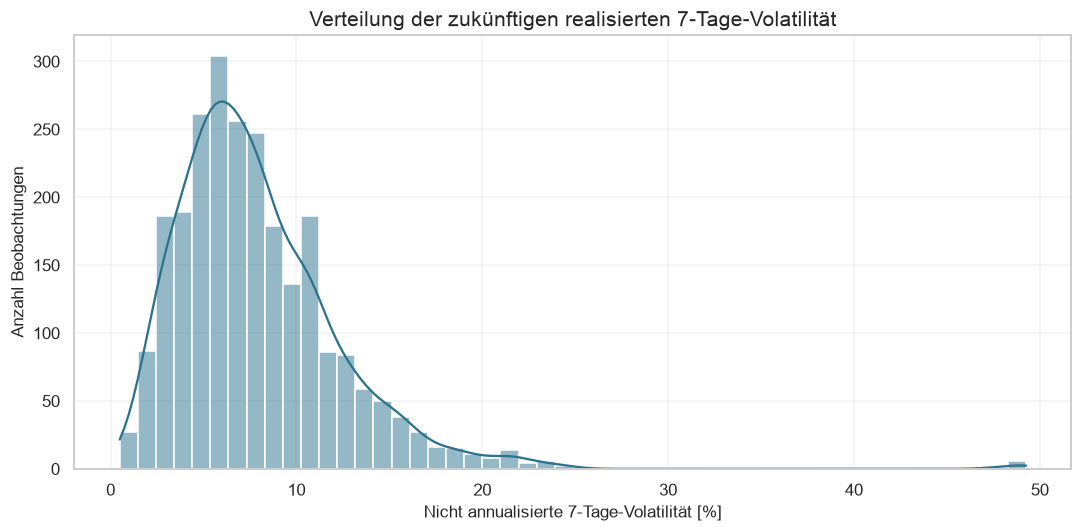

In [15]:
# Show the target distribution in percent without annualizing it
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(
    development_table["target_rv_7"] * 100,
    bins=50,
    kde=True,
    color=COLORS["volatility"],
    ax=ax,
)
ax.set_title("Verteilung der zukünftigen realisierten 7-Tage-Volatilität")
ax.set_xlabel("Nicht annualisierte 7-Tage-Volatilität [%]")
ax.set_ylabel("Anzahl Beobachtungen")
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

In [16]:
# Compare the center and upper tail of the target distribution
target_quantiles = (
    development_table["target_rv_7"]
    .quantile([0.50, 0.75, 0.90, 0.95, 0.99])
    .mul(100)
    .rename("7-Tage-Volatilität [%]")
    .to_frame()
)
display(target_quantiles.round(2))

distribution_skew = development_table["target_rv_7"].skew()
display(
    Markdown(
        f'''
#### Interpretation

Die Zielvariable ist mit einer Schiefe von **{distribution_skew:.2f}**
rechtsschief. Wir verwenden deshalb später sowohl MAE als robuste
Durchschnittsmetrik als auch RMSE, um besonders grosse Prognosefehler sichtbar
zu machen. Die Persistenz-Baseline bleibt wichtig, weil die Zielvariable
zeitlich geglättet und stark abhängig ist.
'''
    )
)

,7-Tage-Volatilität [%]
0.50,7.07
0.75,10.19
0.90,13.30
0.95,15.72
0.99,21.62



#### Interpretation

Die Zielvariable ist mit einer Schiefe von **2.63**
rechtsschief. Wir verwenden deshalb später sowohl MAE als robuste
Durchschnittsmetrik als auch RMSE, um besonders grosse Prognosefehler sichtbar
zu machen. Die Persistenz-Baseline bleibt wichtig, weil die Zielvariable
zeitlich geglättet und stark abhängig ist.


### 6.3 Externe Indikatoren und Bitcoin-Volatilität

#### Erklärung

Fear & Greed, VIX, DXY und Nasdaq haben unterschiedliche Einheiten. Für einen
rein visuellen Vergleich standardisieren wir die bereits verzögerten Niveaus
mit einem Z-Score:

$$
z_t = \frac{x_t-\bar{x}}{s_x}
$$

Wir berechnen Mittelwert und Standardabweichung ausschliesslich im
Entwicklungszeitraum. Diese Standardisierung dient nur der EDA; im späteren
Backtesting darf jede Transformation nur auf dem jeweiligen Trainingsfold
geschätzt werden.

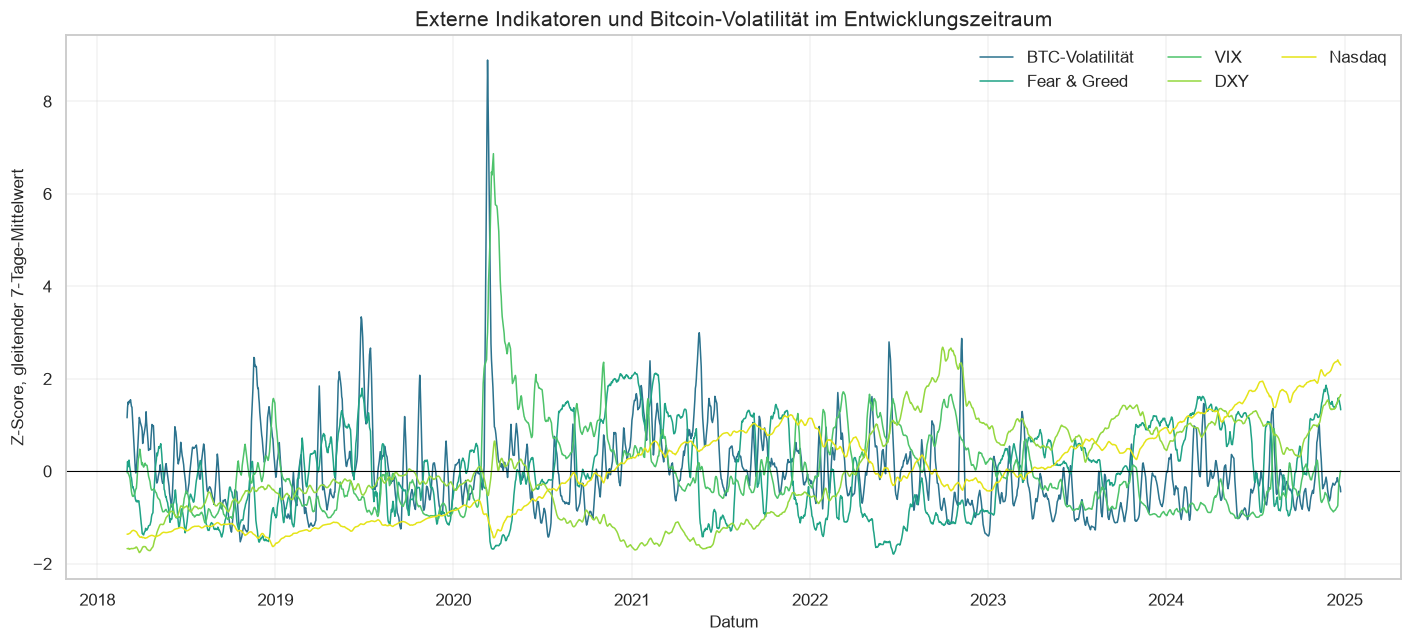

In [17]:
# Use only purged development dates for this exploratory comparison
comparison_levels = aligned.loc[
    development_table.index,
    [
        "target_rv_7_annualized",
        "fear_greed",
        "vix_close",
        "dxy_close",
        "nasdaq_close",
    ],
].dropna()
standardized_levels = (
    comparison_levels - comparison_levels.mean()
) / comparison_levels.std()

# Smooth visual noise without changing the modeling table
standardized_smoothed = standardized_levels.rolling(7, min_periods=1).mean()
display_names = {
    "target_rv_7_annualized": "BTC-Volatilität",
    "fear_greed": "Fear & Greed",
    "vix_close": "VIX",
    "dxy_close": "DXY",
    "nasdaq_close": "Nasdaq",
}
plot_colors = [
    COLORS["volatility"],
    COLORS["fear_greed"],
    COLORS["vix"],
    COLORS["dxy"],
    COLORS["nasdaq"],
]

fig, ax = plt.subplots(figsize=(13, 6))
for column, color in zip(standardized_smoothed.columns, plot_colors):
    ax.plot(
        standardized_smoothed.index,
        standardized_smoothed[column],
        label=display_names[column],
        color=color,
        linewidth=1.0,
    )
ax.axhline(0, color="black", linewidth=0.7)
ax.set_title("Externe Indikatoren und Bitcoin-Volatilität im Entwicklungszeitraum")
ax.set_xlabel("Datum")
ax.set_ylabel("Z-Score, gleitender 7-Tage-Mittelwert")
ax.legend(ncol=3)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

### 6.4 Korrelationen mit der Zielvariable

#### Erklärung

Wir messen lineare Zusammenhänge mit der Pearson-Korrelation ausschliesslich
im Entwicklungszeitraum. Eine Korrelation beweist keine Kausalität und kann
sich zwischen Marktregimen verändern. Sie hilft uns aber, redundante Features
und erste Kandidaten für XGBoost zu erkennen, ohne den Holdout anzusehen.

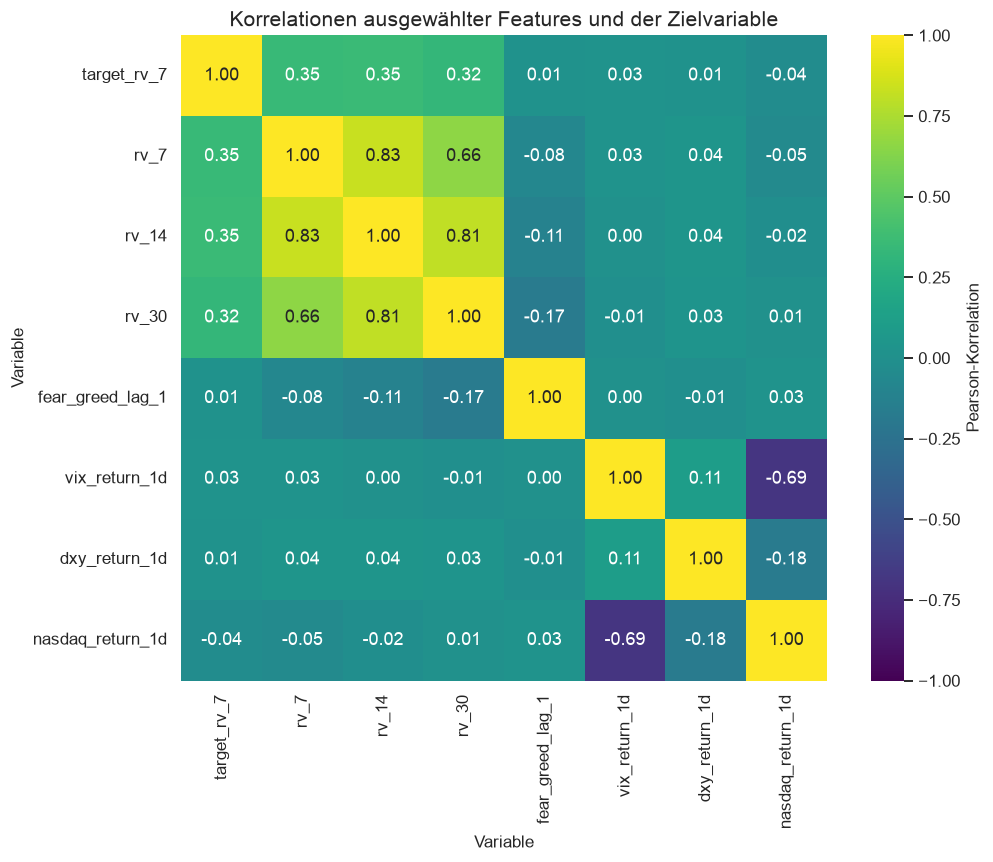

In [18]:
# Keep the heatmap compact and focused on interpretable feature groups
correlation_columns = [
    "target_rv_7",
    "rv_7",
    "rv_14",
    "rv_30",
    "fear_greed_lag_1",
    "vix_return_1d",
    "dxy_return_1d",
    "nasdaq_return_1d",
]
correlation_matrix = development_table[correlation_columns].corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    correlation_matrix,
    cmap="viridis",
    vmin=-1,
    vmax=1,
    center=0,
    annot=True,
    fmt=".2f",
    square=True,
    cbar_kws={"label": "Pearson-Korrelation"},
    ax=ax,
)
ax.set_title("Korrelationen ausgewählter Features und der Zielvariable")
ax.set_xlabel("Variable")
ax.set_ylabel("Variable")
fig.tight_layout()
plt.show()

In [19]:
# Rank absolute correlations with the future volatility target
target_correlations = (
    correlation_matrix["target_rv_7"]
    .drop("target_rv_7")
    .sort_values(key=lambda values: values.abs(), ascending=False)
)
correlation_ranking = target_correlations.rename("Korrelation mit target_rv_7").to_frame()
display(correlation_ranking.round(3))

strongest_feature = target_correlations.index[0]
strongest_correlation = target_correlations.iloc[0]
display(
    Markdown(
        f'''
#### Interpretation

Unter den dargestellten Merkmalen weist **`{strongest_feature}`** mit
**{strongest_correlation:.2f}** den stärksten linearen Zusammenhang zur
zukünftigen 7-Tage-Volatilität auf. Wir erwarten, dass historische
Volatilitätsmerkmale wegen des Volatilitätsclusterings stärker korrelieren als
einzelne tägliche externe Returns. Ob Fear & Greed, VIX, DXY und Nasdaq
zusätzlichen Prognosewert liefern, prüfen wir später ausschliesslich mit
Walk-forward Backtesting.
'''
    )
)

,Korrelation mit target_rv_7
rv_14,0.353
rv_7,0.346
rv_30,0.324
nasdaq_return_1d,-0.038
vix_return_1d,0.028
fear_greed_lag_1,0.014
dxy_return_1d,0.009



#### Interpretation

Unter den dargestellten Merkmalen weist **`rv_14`** mit
**0.35** den stärksten linearen Zusammenhang zur
zukünftigen 7-Tage-Volatilität auf. Wir erwarten, dass historische
Volatilitätsmerkmale wegen des Volatilitätsclusterings stärker korrelieren als
einzelne tägliche externe Returns. Ob Fear & Greed, VIX, DXY und Nasdaq
zusätzlichen Prognosewert liefern, prüfen wir später ausschliesslich mit
Walk-forward Backtesting.


## 7. Übergabe an das purged Walk-forward-Backtesting

### Erklärung

Unsere Validierungsjahre sind 2021 bis 2024. Für einen Fold mit
Validierungsbeginn \(v\) entfernen wir jede Trainingszeile, deren
7-Tage-Zielfenster bis in die Validation reicht:

$$
t + h \geq v
$$

Die Modelle dürfen weiterhin auf allen verbleibenden täglichen Trainingszeilen
lernen. Für die Bewertung verwenden wir aber nur jeden siebten
Prognoseursprung. Dadurch überlappen sich die Evaluationsziele nicht.

Der Zeitraum ab 2025 bleibt vollständig ausserhalb dieser Folds und wird erst
nach Abschluss aller Modellentscheidungen einmalig ausgewertet.

In [20]:
# Build annual validation folds without touching the final holdout
fold_rows = []
evaluation_origins = {}

for validation_year in VALIDATION_YEARS:
    validation_start = pd.Timestamp(f"{validation_year}-01-01")
    validation_end = pd.Timestamp(f"{validation_year + 1}-01-01")

    # Purge every training label that reaches the validation period
    train_fold = development_table[
        development_table["target_end"] < validation_start
    ].copy()

    # Keep only validation targets fully contained in the validation year
    validation_candidates = development_table[
        (development_table.index >= validation_start)
        & (development_table["target_end"] < validation_end)
    ].copy()

    # Evaluate every seventh origin to avoid overlapping seven-day targets
    validation_origins = validation_candidates.index[::EVALUATION_STEP_DAYS]
    evaluation_origins[validation_year] = validation_origins

    # Validate the purge and spacing contracts
    assert not train_fold.empty
    assert not validation_origins.empty
    assert train_fold["target_end"].max() < validation_start
    if len(validation_origins) > 1:
        origin_spacing = pd.Series(validation_origins).diff().dropna().dt.days
        assert (origin_spacing >= FORECAST_HORIZON).all()

    fold_rows.append(
        {
            "Fold": f"Validation {validation_year}",
            "Training bis": train_fold.index.max().date(),
            "Letztes Trainingsziel endet": train_fold["target_end"].max().date(),
            "Validation von": validation_origins.min().date(),
            "Validation bis": validation_origins.max().date(),
            "Trainingszeilen": len(train_fold),
            "Evaluationsursprünge": len(validation_origins),
            "Purge bestanden": "ja",
        }
    )

fold_overview = pd.DataFrame(fold_rows)
display(fold_overview)

,Fold,Training bis,Letztes Trainingsziel endet,Validation von,Validation bis,Trainingszeilen,Evaluationsursprünge,Purge bestanden
0,Validation 2021,2020-12-24,2020-12-31,2021-01-01,2021-12-24,1024,52,ja
1,Validation 2022,2021-12-24,2021-12-31,2022-01-01,2022-12-24,1389,52,ja
2,Validation 2023,2022-12-24,2022-12-31,2023-01-01,2023-12-24,1754,52,ja
3,Validation 2024,2023-12-24,2023-12-31,2024-01-01,2024-12-23,2119,52,ja


In [21]:
# Summarize the fold handoff from executed checks
total_evaluation_origins = sum(len(origins) for origins in evaluation_origins.values())
first_holdout_origin = holdout_table.index.min()

display(
    Markdown(
        f'''
### Interpretation

Alle **{len(fold_overview)} Validierungsfolds** bestehen die Purge-Prüfung.
Insgesamt stehen **{total_evaluation_origins} nicht überlappende
Evaluationsursprünge** zur Verfügung. Der Holdout beginnt am
**{first_holdout_origin.date()}** und ist in keinem Validierungsfold enthalten.

Für Chronos-2 verwenden wir später die bis \(t\) beobachtete rückwärts
blickende Reihe `rv_7`, prognostizieren sieben Schritte und nehmen Schritt 7:

$$
\widehat{{\mathrm{{target\_rv7}}}}_t
=
\widehat{{\mathrm{{rv7}}}}_{{t+7}}
$$

Die forward-looking Reihe `target_rv_7` darf niemals als am Tag \(t\)
verfügbarer Chronos-Kontext verwendet werden.
'''
    )
)


### Interpretation

Alle **4 Validierungsfolds** bestehen die Purge-Prüfung.
Insgesamt stehen **208 nicht überlappende
Evaluationsursprünge** zur Verfügung. Der Holdout beginnt am
**2025-01-01** und ist in keinem Validierungsfold enthalten.

Für Chronos-2 verwenden wir später die bis \(t\) beobachtete rückwärts
blickende Reihe `rv_7`, prognostizieren sieben Schritte und nehmen Schritt 7:

$$
\widehat{\mathrm{target\_rv7}}_t
=
\widehat{\mathrm{rv7}}_{t+7}
$$

Die forward-looking Reihe `target_rv_7` darf niemals als am Tag \(t\)
verfügbarer Chronos-Kontext verwendet werden.


## 8. Zwischenfazit und nächste Schritte

### Erklärung

Wir haben nun eine qualitätsgeprüfte, leakage-bewusste Modelling-Tabelle, einen
unberührten Holdout und geprüfte Walk-forward-Foldgrenzen. Die EDA allein
beantwortet die Forschungsfrage noch nicht.

### Code und Ergebnis

Die Datei `data/processed/bitcoin_volatility_modeling_table.csv` wurde
reproduzierbar erzeugt. Sie bleibt lokal und wird nicht auf GitHub versioniert,
weil alle Quelldaten mit dem festen Stichtag erneut geladen werden können.

### Interpretation

Als nächsten Teil ergänzen wir auf den bereits definierten Fold- und
Evaluationsursprüngen:

1. MAE und RMSE,
2. naive Persistenz und gleitende Mittelwerte,
3. GARCH mit konsistenter Aggregation der sieben prognostizierten Varianzen,
4. XGBoost mit den festgelegten Feature-Sets,
5. Chronos-2 mit `rv_7` als Kontext und Forecast-Schritt 7 als Zielprognose.

Lightning verwenden wir nicht, solange kein eigenes PyTorch-Modell trainiert
wird. Für Zero-Shot-Inferenz mit Chronos-2 genügt die direkte Modell-API.